# MJO Hovmöller diagrams

## Purpose

Compare the eastward propagation of tropical convection (OLR, precipitation) in each experiment with observations.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Daily FLUT and PRECT (`ts/daily/1yr`, labelled by the day they cover). Observations under `OBSERVATION_ROOT`: NOAA interpolated OLR and GPM IMERG daily (E3SM Diags time series).

## Method

Daily anomalies (period mean plus 3 annual harmonics removed; `SEASONAL_CYCLE`), averaged over 10S-10N (cos-lat weights), standardized by their own std. Panel titles give the pattern correlation and RMSE against observations over the plotted days (model days only; the noleap model has no Feb 29).

## Outputs

`data/hind_atm_mjo/mjo/mjo_hov_<SOURCE>_<VAR>_<period>.nc` (`OBS` for observations) and `figure/hind_atm_mjo/mjo/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_mjo"

# Experiments: run key (file names, tables) -> figure label. Labels follow fcst_atm_eval: the experiment
# whose initial state the run starts from (CTRL10: piControl, CAPT10: ERA5, DART40: DART), written
# "<atm>A-<lnd>L" when atmosphere and land come from different ones. EXPERIMENTS_FULL (backup) is the full
# atm x lnd factorial, needed for the initial-state attribution (factorial effects and noise floors).
EXPERIMENTS_FULL = {
    "CTRL": "CTRL10-S0",           # piControl atm + piControl lnd
    "DARTOP": "DART40-S0",         # DART atm + DART lnd
    "ERA5OP": "CAPT10-S0",         # ERA5 atm + ERA5-forced lnd
    "ERA5DL": "CAPTA-DARTL-S0",    # ERA5 atm + DART lnd
    "ERA5BL": "CAPTA-CTRLL-S0",    # ERA5 atm + piControl lnd
    "DARTBL": "DARTA-CTRLL-S0",    # DART atm + piControl lnd
    "DARTBA": "CTRLA-DARTL-S0",    # piControl atm + DART lnd
    "DARTAE": "DARTA-CAPTL-S0",    # DART atm + ERA5-forced lnd
}
EXPERIMENTS_FCST = {k: EXPERIMENTS_FULL[k] for k in ("CTRL", "ERA5OP", "DARTOP")}
EXPERIMENTS = EXPERIMENTS_FCST  # or EXPERIMENTS_FULL
VARIABLES = ("FLUT", "PRECT")
LAT_BAND = (-10.0, 10.0)
LON_SECTOR = (0.0, 360.0)
SEASONAL_CYCLE = "harmonics"  # "harmonics" | "daily_climatology" | "none"
PLOT_DAYS = (0, 120)  # days since 2012-01-01 shown
FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask
from util.hind_factorial import relabel_figure

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'mjo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
FACTORIAL = set(EXPERIMENTS) == set(EXPERIMENTS_FULL)  # the atm x lnd attribution needs all 8 runs
SET_NAME = "full" if FACTORIAL else "fcst_aligned" if set(EXPERIMENTS) == set(EXPERIMENTS_FCST) else "subset"
table_dir = data_dir
if not FACTORIAL:  # tables and figures of a subset kept apart from the full set; per-source files are shared
    table_dir, figure_dir = data_dir / SET_NAME, figure_dir / SET_NAME
    for d in (table_dir, figure_dir):
        d.mkdir(exist_ok=True)
print(f"[DATA] {data_dir}\n[TABLE] {table_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    relabel_figure(fig, EXPERIMENTS_FULL)  # run keys -> figure labels
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_mjo/mjo
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_mjo/mjo/fcst_aligned
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_mjo/mjo/fcst_aligned


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from util.mjo_hovmoller_coupling import hov_path, open_mjo_input

SOURCES = ("OBS", *EXPERIMENTS)
lat_range = (min(LAT_BAND) - 5, max(LAT_BAND) + 5)
paths = {(s, v): hov_path(data_dir, s, v) for s in SOURCES for v in VARIABLES}
inputs = {key: open_mjo_input(*key, data_root=INPUT_DATA_ROOT, lat_range=lat_range, **ROOTS)
          for key, path in paths.items() if FORCE_COMPUTE or not path.exists()}
print(f"[READ] {', '.join(f'{s} {v}' for s, v in inputs) or 'nothing: every Hovmöller is saved'}")

[READ] nothing: every Hovmöller is saved


## 5. Derive

Standardized lat-band-mean anomalies (time, lon) per source and variable. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.mjo_hovmoller_coupling import MjoConfig, MjoDiagnostics

cfg = MjoConfig(lat_band=LAT_BAND, hov_lon_sector=LON_SECTOR, seasonal_cycle=SEASONAL_CYCLE)
diag = MjoDiagnostics(cfg)
bands = compute_all({key: diag.hov_reduce(da) for key, da in inputs.items()})
derived = {key: diag.hov_finish(band).rename("hov") for key, band in bands.items()}

## 6. Save

In [6]:
for (s, v), hov in derived.items():
    hov.to_dataset().assign_attrs(source=s, variable=v, lon_sector=str(cfg.hov_lon_sector),
                                  lat_band=str(cfg.lat_band), seasonal_cycle=cfg.seasonal_cycle,
                                  n_harmonics=cfg.n_harmonics).to_netcdf(paths[s, v])
    print(f"[WRITE] {paths[s, v]}")

## 7. Plot and show

From the saved files.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_mjo/mjo/fcst_aligned/mjo_hov_grid_FLUT_days0-120.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_mjo/mjo/fcst_aligned/mjo_hov_grid_PRECT_days0-120.png


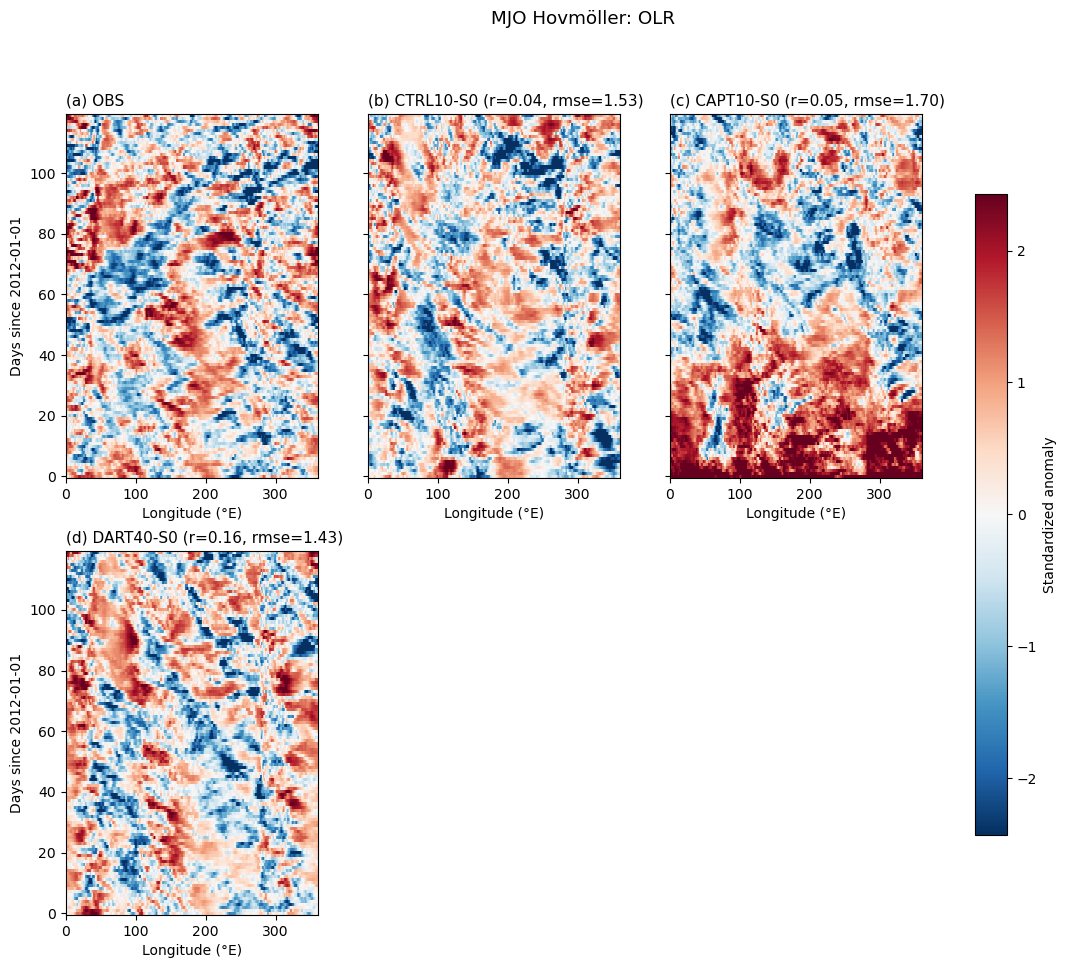

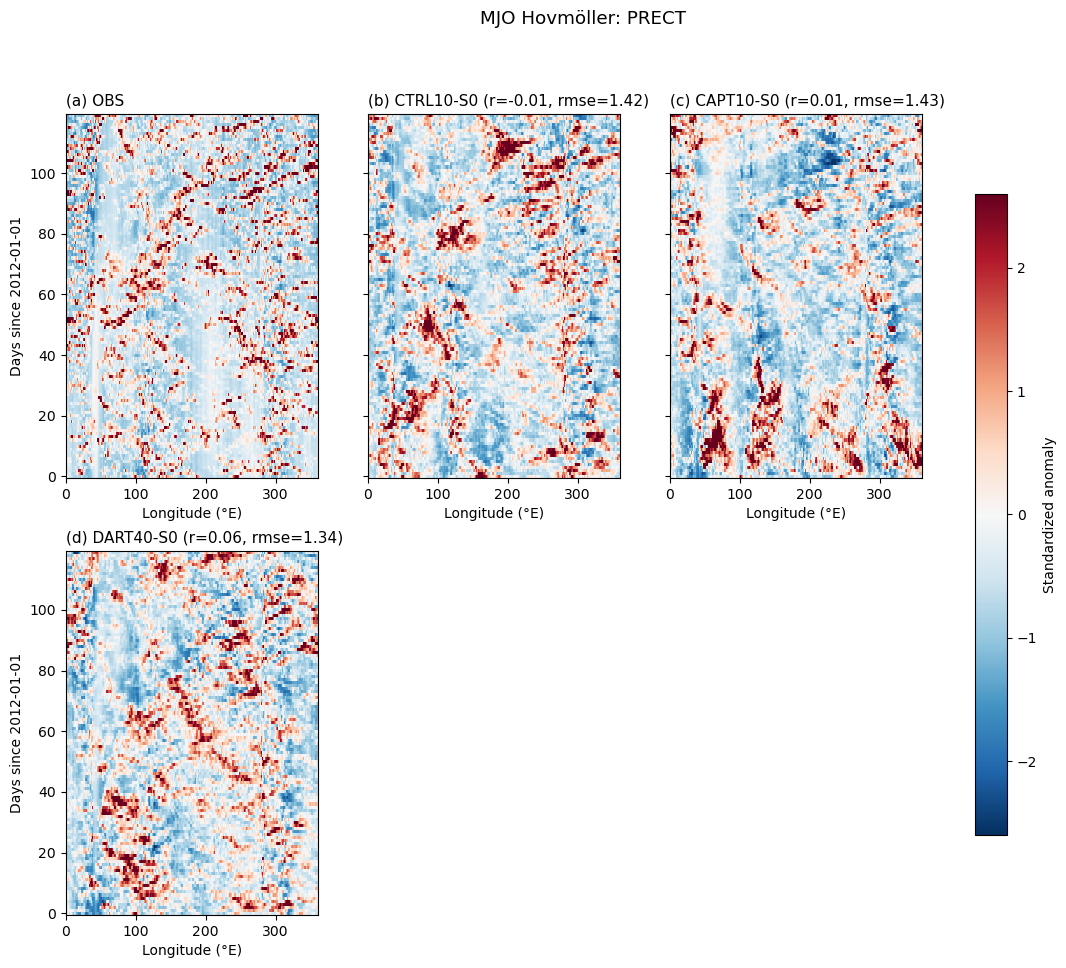

In [7]:
from util.mjo_hovmoller_coupling import plot_hovmoller_grid

for var in VARIABLES:
    fig = plot_hovmoller_grid(data_dir, var, EXPERIMENTS, days=PLOT_DAYS)
    save(fig, f"mjo_hov_grid_{var}_days{PLOT_DAYS[0]}-{PLOT_DAYS[1]}.png")